# Арзамас: полный пайплайн BlocksNet 1.0.0a9

**Территория:** Арзамас, Нижегородская область
**Данные:** OpenStreetMap (скачиваются автоматически при первом запуске)

Этот ноутбук повторяет официальный pipeline BlocksNet для Арзамаса:

1. Скачивается граница города и слои OSM (вода, дороги, железные дороги);
2. Нарезаются кварталы и определяется землепользование (land use);
3. **STOP** — можно проверить, как легли кварталы, прежде чем считать дальше;
4. Строится автомобильный граф из OSM и матрица времени в пути (минуты);
5. Скачиваются здания, достраиваются пропуски, считается население;
6. Школы и обеспеченность ими (competitive provision);
7. Плотность (FSI, GSI, MXI, L, OSR) и морфотипы (Spacematrix, Strelka);
8. Доступность по площади кварталов;
9. Всё сводится в один файл `blocks_metrics.geojson` — из него на следующем этапе будет собрана интерактивная карта и дашборд.

**Как запускать:** ядро — «BlocksNet (Arzamas)», ячейки — сверху вниз. Первый запуск (с интернетом) занимает 10–30 минут: скачивание данных OSM и расчёт графа. При перегрузке серверов OSM ноутбук сам делает паузы и повторяет запрос через другие зеркала Overpass, а тяжёлый слой дорог скачивает тремя частями — каждая часть сразу сохраняется в кэш, поэтому прерванный запуск продолжается с места остановки. Повторные запуски берут всё из кэша `examples/data/arzamas/` и проходят быстро.


In [1]:
import pickle
import time
from enum import Enum
from pathlib import Path

import geopandas as gpd
import numpy as np
import osmnx as ox
import pandas as pd
from shapely.geometry import box

from blocksnet.config import service_types_config

CWD = Path.cwd()
if (CWD / 'examples').is_dir():
    DATA_DIR = CWD / 'examples' / 'data' / 'arzamas'
else:
    DATA_DIR = CWD / 'data' / 'arzamas'
DATA_DIR.mkdir(parents=True, exist_ok=True)

TERRITORY = 'Арзамас, Нижегородская область, Россия'
GRAPH_TYPE = 'drive'
SERVICE_TYPE = 'school'

OVERPASS_URLS = [
    'https://overpass-api.de/api',
    'https://overpass.kumi.systems/api',
    'https://maps.mail.ru/osm/tools/overpass/api',
    'https://overpass.private.coffee/api',
]
ox.settings.overpass_url = OVERPASS_URLS[0]

import osmnx._overpass as _osmnx_overpass

_overpass_busy = False
_osmnx_overpass_request = _osmnx_overpass._overpass_request


def _overpass_request_once(data):
    global _overpass_busy
    if _overpass_busy:
        raise ConnectionError('Overpass-сервер перегружен (код 429/504), переходим на другое зеркало')
    _overpass_busy = True
    try:
        return _osmnx_overpass_request(data)
    finally:
        _overpass_busy = False


_osmnx_overpass._overpass_request = _overpass_request_once

import threading

import requests as _requests


def _post_with_deadline(url, **kwargs):
    result = {}

    def worker():
        try:
            result['response'] = _requests.post(url, **kwargs)
        except Exception as error:
            result['error'] = error

    thread = threading.Thread(target=worker, daemon=True)
    thread.start()
    thread.join(240)
    if thread.is_alive():
        raise TimeoutError('Overpass-сервер не отдал ответ за 4 минуты')
    if 'error' in result:
        raise result['error']
    return result['response']


class _RequestsWithDeadline:
    Request = _requests.Request
    get = staticmethod(_requests.get)
    post = staticmethod(_post_with_deadline)


_osmnx_overpass.requests = _RequestsWithDeadline

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 220)


def read_cache(filename):
    path = DATA_DIR / filename
    if not path.exists():
        return None
    gdf = gpd.read_file(path)
    if 'block_id' in gdf.columns:
        gdf = gdf.set_index('block_id')
        gdf.index = gdf.index.astype(int)
        gdf = gdf.sort_index()
    print(f'Загружено из кэша: {filename} ({len(gdf)} объектов)')
    return gdf


def _flatten(value):
    if isinstance(value, Enum):
        return value.value
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if isinstance(value, (list, tuple, set, dict)):
        return str(value)
    return value


def write_cache(gdf, filename):
    flat = gdf.copy().reset_index(drop=True)
    for column in flat.columns:
        if column != flat.geometry.name:
            flat[column] = flat[column].map(_flatten)
    flat.to_crs(4326).to_file(DATA_DIR / filename, driver='GeoJSON')
    print(f'Сохранено в кэш: {filename} ({len(flat)} объектов)')


def read_matrix(filename):
    path = DATA_DIR / filename
    if not path.exists():
        return None
    matrix = pd.read_csv(path, index_col=0)
    matrix.index = matrix.index.astype(int)
    matrix.columns = matrix.columns.astype(int)
    print(f'Загружено из кэша: {filename} {matrix.shape}')
    return matrix


def write_matrix(matrix, filename):
    matrix.to_csv(DATA_DIR / filename)
    print(f'Сохранено в кэш: {filename} {matrix.shape}')


LOG_FILE = DATA_DIR / 'download_log.txt'


def log_download(message):
    line = f'[{time.strftime("%H:%M:%S")}] {message}'
    print(line)
    with open(LOG_FILE, 'a', encoding='utf-8') as file:
        print(line, file=file)


def plot_gdf(gdf, column=None, **kwargs):
    ax = gdf.plot(column=column, **kwargs)
    ax.set_axis_off()
    return ax


def download_features(polygon, tags, attempts=25):
    empty_servers = set()
    for attempt in range(attempts):
        url = OVERPASS_URLS[attempt % len(OVERPASS_URLS)]
        ox.settings.overpass_url = url
        server = url.split('/')[2]
        error_text = 'пустой ответ'
        error_name = 'EmptyResponse'
        try:
            features = ox.features_from_polygon(polygon, tags).reset_index(drop=True)
            if len(features) > 0:
                log_download(f'OSM: скачано {len(features)} объектов (сервер {server})')
                return features
        except Exception as error:
            error_text = str(error)
            error_name = type(error).__name__
        if 'No matching features' in error_text or 'пустой ответ' in error_text:
            empty_servers.add(server)
            if len(empty_servers) >= len(OVERPASS_URLS):
                log_download('OSM: подходящих объектов нет ни на одном сервере')
                return gpd.GeoDataFrame(geometry=[], crs=4326)
            log_download(f'OSM: сервер {server} вернул пустой ответ, пробуем другой сервер...')
            time.sleep(10)
        else:
            wait = min(20 * (attempt + 1), 180)
            log_download(f'OSM: сервер {server} не ответил ({error_name}), пауза {wait} с и продолжаем...')
            time.sleep(wait)
    raise RuntimeError('Не удалось скачать данные OSM: все Overpass-серверы заняты, попробуйте запустить позже')


ROADS_TAG_GROUPS = [
    {
        'highway': ['motorway', 'motorway_link', 'trunk', 'trunk_link', 'primary', 'primary_link',
                    'secondary', 'secondary_link', 'tertiary', 'tertiary_link'],
    },
    {
        'highway': ['residential', 'unclassified', 'living_street', 'pedestrian'],
    },
    {
        'highway': ['road', 'track', 'raceway', 'services', 'construction', 'crossing', 'motorway_junction',
                    'turning_circle', 'turning_loop'],
        'service': ['living_street', 'emergency_access'],
    },
]


def download_roads(polygon):
    parts = []
    for index, part_tags in enumerate(ROADS_TAG_GROUPS, start=1):
        filename = f'roads_part{index}.geojson'
        part = read_cache(filename)
        if part is None:
            log_download(f'Качаем дороги, часть {index} из {len(ROADS_TAG_GROUPS)}...')
            part = download_features(polygon, part_tags)
            part = part[part.geom_type.isin(['LineString', 'MultiLineString'])].copy()
            write_cache(part, filename)
        parts.append(part)
    roads = pd.concat(parts, ignore_index=True)
    roads = roads.drop_duplicates(subset='geometry').reset_index(drop=True).copy()
    log_download(f'Дороги: {len(roads)} линий (части объединены, дубликаты убраны)')
    return roads


def download_buildings(polygon):
    minx, miny, maxx, maxy = polygon.bounds
    tiles = []
    for i in range(3):
        for j in range(3):
            x0 = minx + (maxx - minx) * i / 3
            x1 = minx + (maxx - minx) * (i + 1) / 3
            y0 = miny + (maxy - miny) * j / 3
            y1 = miny + (maxy - miny) * (j + 1) / 3
            tiles.append(box(x0, y0, x1, y1))
    parts = []
    for index, tile in enumerate(tiles, start=1):
        filename = f'buildings_part{index}.geojson'
        part = read_cache(filename)
        if part is None:
            piece = polygon.intersection(tile)
            if piece.is_empty:
                log_download(f'Здания, квадрат {index} из {len(tiles)}: вне границ города, пропускаем')
                continue
            log_download(f'Качаем здания, квадрат {index} из {len(tiles)}...')
            part = download_features(piece, {'building': True})
            part = part[part.geom_type.isin(['Polygon', 'MultiPolygon'])].copy()
            write_cache(part, filename)
        parts.append(part)
    buildings = pd.concat(parts, ignore_index=True)
    buildings = buildings.drop_duplicates(subset='geometry').reset_index(drop=True).copy()
    log_download(f'Здания: {len(buildings)} объектов (квадраты объединены, дубликаты убраны)')
    return buildings


print(f'Папка кэша: {DATA_DIR}')

Папка кэша: C:\Users\Мария\Desktop\ИИ 3 семестр\python-package-boilerplate\examples\data\arzamas


## 1. Границы территории

### 1.1. Граница Арзамаса

Граница скачивается из OSM (Nominatim) и сохраняется в кэш `boundary.geojson`.

Загружено из кэша: boundary.geojson (1 объектов)


Используемая проекция: WGS 84 / UTM zone 38N


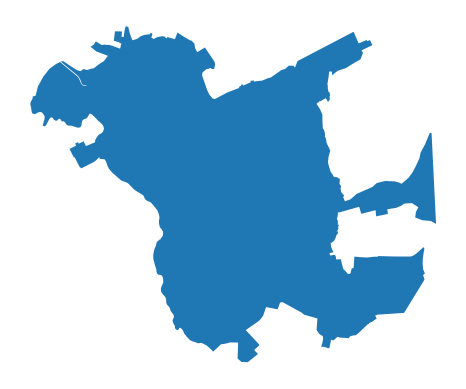

In [2]:
boundaries = read_cache('boundary.geojson')
if boundaries is None:
    boundaries = ox.geocode_to_gdf(TERRITORY)
    write_cache(boundaries, 'boundary.geojson')

crs = boundaries.estimate_utm_crs()
boundaries = boundaries.to_crs(crs)

plot_gdf(boundaries)
print(f'Используемая проекция: {crs.name}')

### 1.2. Слои OSM (вода, дороги, железные дороги)

Теги такие же, как в официальном pipeline BlocksNet.

In [3]:
bc_tags = {
    'roads': {
        'highway': ['construction', 'crossing', 'living_street', 'motorway', 'motorway_link', 'motorway_junction', 'pedestrian', 'primary', 'primary_link', 'raceway', 'residential', 'road', 'secondary', 'secondary_link', 'services', 'tertiary', 'tertiary_link', 'track', 'trunk', 'trunk_link', 'turning_circle', 'turning_loop', 'unclassified'],
        'service': ['living_street', 'emergency_access'],
    },
    'railways': {
        'railway': 'rail',
    },
    'water': {
        'riverbank': True,
        'reservoir': True,
        'basin': True,
        'dock': True,
        'canal': True,
        'pond': True,
        'natural': ['water', 'bay'],
        'waterway': ['river', 'canal', 'ditch'],
        'landuse': 'basin',
        'water': 'lake',
    },
}

boundary_polygon = boundaries.to_crs(4326).union_all()

water = read_cache('water.geojson')
if water is None:
    water = download_features(boundary_polygon, bc_tags['water'])
    water = water[water.geom_type.isin(['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])].copy()
    write_cache(water, 'water.geojson')
water = water.to_crs(crs)

roads = read_cache('roads.geojson')
if roads is None:
    roads = download_roads(boundary_polygon)
    write_cache(roads, 'roads.geojson')
roads = roads.to_crs(crs)

railways = read_cache('railways.geojson')
if railways is None:
    railways = download_features(boundary_polygon, bc_tags['railways'])
    railways = railways[railways.geom_type.isin(['LineString', 'MultiLineString'])].copy()
    write_cache(railways, 'railways.geojson')
railways = railways.to_crs(crs)

print(f'Вода: {len(water)}, дороги: {len(roads)}, железные дороги: {len(railways)}')

Загружено из кэша: water.geojson (170 объектов)
Загружено из кэша: roads.geojson (766 объектов)


Загружено из кэша: railways.geojson (126 объектов)
Вода: 170, дороги: 766, железные дороги: 126


### 1.3. Нарезка кварталов

Кварталы режутся линиями дорог и железных дорог, минус вода — как в официальном pipeline.

C:\Users\Мария\Desktop\ИИ 3 семестр\python-package-boilerplate\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Загружено из кэша: blocks_raw.geojson (403 объектов)
Получилось кварталов: 403


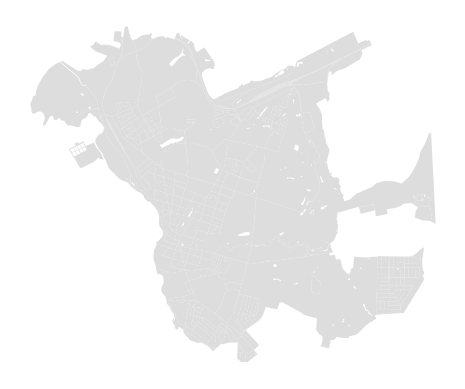

In [4]:
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects

blocks = read_cache('blocks_raw.geojson')
if blocks is None:
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundaries, lines, polygons)
    write_cache(blocks.assign(block_id=blocks.index), 'blocks_raw.geojson')
blocks = blocks.to_crs(crs)

plot_gdf(blocks, color='#dddddd')
print(f'Получилось кварталов: {len(blocks)}')

## 2. Землепользование

### 2.1. Функциональные зоны OSM

Функциональные зоны (landuse) скачиваются из OSM; затем каждому кварталу присваивается землепользование по правилам, как в официальном pipeline.

In [5]:
functional_zones = read_cache('functional_zones.geojson')
if functional_zones is None:
    functional_zones = download_features(boundaries.to_crs(4326).union_all(), {'landuse': True})
    functional_zones = functional_zones[functional_zones.geom_type.isin(['Polygon', 'MultiPolygon'])].reset_index(drop=True)
    functional_zones = functional_zones[['geometry', 'landuse']].rename(columns={'landuse': 'functional_zone'})
    write_cache(functional_zones, 'functional_zones.geojson')
functional_zones = functional_zones.to_crs(crs)

functional_zones.head()

Загружено из кэша: functional_zones.geojson (819 объектов)


,functional_zone,geometry
0,residential,"POLYGON ((424646.543 6139998.864, 424627.475 6..."
1,farmland,"POLYGON ((421750.266 6141021.925, 421833.942 6..."
2,farmland,"POLYGON ((422778.765 6139990.876, 422963.043 6..."
3,allotments,"POLYGON ((424062.523 6142332.804, 424038.762 6..."
4,allotments,"POLYGON ((422282.056 6141740.806, 422309.585 6..."


Загружено из кэша: blocks_land_use.geojson (403 объектов)


land_use
residential    271
нет данных      91
industrial      29
business         5
special          3
recreation       3
agriculture      1


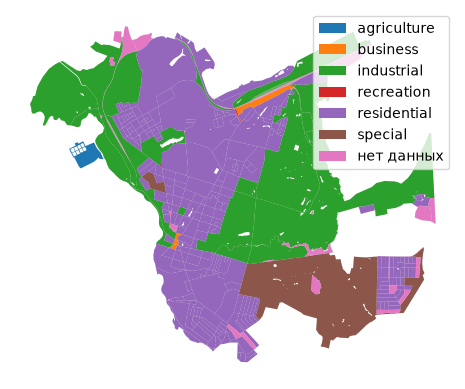

In [6]:
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

rules = {
    'commercial': LandUse.BUSINESS,
    'industrial': LandUse.INDUSTRIAL,
    'cemetery': LandUse.SPECIAL,
    'garages': LandUse.INDUSTRIAL,
    'residential': LandUse.RESIDENTIAL,
    'retail': LandUse.BUSINESS,
    'grass': LandUse.RECREATION,
    'farmland': LandUse.AGRICULTURE,
    'construction': LandUse.SPECIAL,
    'brownfield': LandUse.INDUSTRIAL,
    'forest': LandUse.RECREATION,
    'recreation_ground': LandUse.RECREATION,
    'religious': LandUse.SPECIAL,
    'flowerbed': LandUse.RECREATION,
    'military': LandUse.SPECIAL,
    'landfill': LandUse.TRANSPORT,
}

blocks_land_use = read_cache('blocks_land_use.geojson')
if blocks_land_use is None:
    blocks = assign_land_use(blocks, functional_zones, rules)
    blocks_land_use = blocks
    write_cache(blocks_land_use.assign(block_id=blocks_land_use.index), 'blocks_land_use.geojson')
blocks = blocks_land_use.to_crs(crs)


def _land_use_name(value):
    if isinstance(value, LandUse):
        return value.value
    if isinstance(value, str):
        return value
    return 'нет данных'


plot_blocks = blocks.assign(land_use_name=blocks.land_use.map(_land_use_name))
ax = plot_blocks.plot(color='#dddddd')
plot_blocks.plot(column='land_use_name', legend=True, ax=ax)
ax.set_axis_off()
print(blocks.land_use.map(_land_use_name).value_counts().to_string())

---

## STOP: проверка кварталов

Уже сохранены в `examples/data/arzamas/`:

- `blocks_raw.geojson` — нарезанные кварталы;
- `blocks_land_use.geojson` — кварталы с землепользованием.

**Посмотрите на две карты выше и убедитесь, что кварталы нарезаны разумно.** Если что-то выглядит странно — это лучший момент, чтобы это заметить: дальше все расчёты опираются на кварталы.

Можно поменять настройки в первой ячейке:

- `SERVICE_TYPE` — вид сервиса (по умолчанию школы). Список всех сервисов конфига BlocksNet печатается в следующей ячейке;
- `GRAPH_TYPE` — `drive` (автомобильные поездки; используется сейчас). Готового архива с графом для Арзамаса нет (в blocksnet-data есть только Санкт-Петербург), поэтому граф строится из OSM автоматически в следующем разделе.

Когда посмотрели — продолжайте запускать ячейки ниже.

In [7]:
import pkgutil

import blocksnet.analysis as analysis_package

service_names = sorted(service_types_config)
print(f'Сервисов в конфиге BlocksNet: {len(service_names)}')
print(', '.join(service_names))
print()
modules = sorted(module.name for module in pkgutil.iter_modules(analysis_package.__path__))
print('Модули blocksnet.analysis: ' + ', '.join(modules))

Сервисов в конфиге BlocksNet: 82
aeroway_terminal, agricultural_services, animal_shelter, bakery, bank, bar, beach, bus_station, bus_stop, cafe, car_wash, cemetery, chemical, cinema, circus, college, construction, convenience, court_house, crematorium, diplomatic, dog_park, electronics_industry, embankment, energy, engineering, farmland, food_industry, fuel, gallery, golf_course, government, guest_house, hairdresser, hospital, hostel, hotel, houseware, kindergarten, landfill, lawyer, library, light_industry, mall, market, metallurgy, monastery, multifunctional_center, museum, notary, park, parking, pharmacy, pier, pitch, playground, police, polyclinic, post, prison, recruitment, religion, reserve, restaurant, sanatorium, school, social_facility, stadium, substation, subway_entrance, supermarket, swimming_pool, theatre, train_building, train_station, university, veterinary, warehouse, wastewater_plant, water_works, woodworking, zoo

Модули blocksnet.analysis: centrality, diversity, geom

## 3. Граф и матрица времени в пути

Автомобильный граф **drive** строится из данных OSM. Вес ребра — `time_min` (минуты). При первом запуске это занимает несколько минут; граф сохранится в `graph_drive.pickle`, матрица — в `acc_mx_drive.csv` (время между кварталами в минутах).

In [8]:
from blocksnet.relations import get_accessibility_graph

graph_path = DATA_DIR / f'graph_{GRAPH_TYPE}.pickle'
if graph_path.exists():
    with open(graph_path, 'rb') as file:
        graph = pickle.load(file)
    print(f'Граф загружен из кэша: {graph_path.name}')
else:
    log_download('Строим автомобильный граф из OpenStreetMap (это может занять несколько минут)...')
    for attempt in range(15):
        try:
            graph = get_accessibility_graph(boundaries, GRAPH_TYPE)
            break
        except Exception as error:
            wait = min(30 * (attempt + 1), 180)
            log_download(f'Граф не построился ({type(error).__name__}), пауза {wait} с и пробуем снова...')
            time.sleep(wait)
    else:
        raise RuntimeError('Не удалось построить граф из OSM: серверы заняты, попробуйте запустить позже')
    with open(graph_path, 'wb') as file:
        pickle.dump(graph, file)
    print(f'Граф сохранён в кэш: {graph_path.name} ({graph_path.stat().st_size / 1e6:.1f} МБ)')

print(f'Узлов: {graph.number_of_nodes():,}, рёбер: {graph.number_of_edges():,}')

_, node_data = next(iter(graph.nodes(data=True)))
assert 'x' in node_data and 'y' in node_data, 'в узлах графа нет координат x/y'
edge_attributes = next(iter(graph.edges(keys=False, data=True)))[2]
assert 'time_min' in edge_attributes, 'в рёбрах графа нет времени time_min'
print('Граф корректен: в узлах есть координаты x/y, в рёбрах — время time_min (минуты)')

Граф загружен из кэша: graph_drive.pickle
Узлов: 785, рёбер: 2,099
Граф корректен: в узлах есть координаты x/y, в рёбрах — время time_min (минуты)


In [9]:
from blocksnet.relations import calculate_accessibility_matrix

acc_mx = read_matrix(f'acc_mx_{GRAPH_TYPE}.csv')
if acc_mx is None:
    print('Считаем матрицу времени в пути между кварталами (минуты)...')
    acc_mx = calculate_accessibility_matrix(blocks, graph)
    write_matrix(acc_mx, f'acc_mx_{GRAPH_TYPE}.csv')

values = acc_mx.to_numpy(dtype=float, copy=True)
finite_max = float(values[np.isfinite(values)].max())
values[~np.isfinite(values)] = finite_max
np.fill_diagonal(values, 0.0)
acc_mx = pd.DataFrame(values, index=acc_mx.index, columns=acc_mx.columns)

assert acc_mx.shape == (len(blocks), len(blocks))
assert int(acc_mx.isna().sum().sum()) == 0
assert list(acc_mx.index) == list(blocks.index)

print(f'Матрица готова: {acc_mx.shape[0]} x {acc_mx.shape[1]} кварталов')
print(f'Среднее время в пути между кварталами: {acc_mx.to_numpy().mean():.1f} мин')

Загружено из кэша: acc_mx_drive.csv (403, 403)
Матрица готова: 403 x 403 кварталов
Среднее время в пути между кварталами: 9.1 мин


## 4. Здания и население

Здания скачиваются из OSM. Пропуски достраиваются модулем `impute_buildings` (норматив жилой обеспеченности 30 м²/чел.), затем данные агрегируются по кварталам.

In [10]:
buildings = read_cache('buildings.geojson')
if buildings is None:
    buildings = download_buildings(boundaries.to_crs(4326).union_all())
    is_living_tags = ['residential', 'house', 'apartments', 'detached', 'terrace', 'dormitory']
    buildings['is_living'] = buildings['building'].apply(lambda value: value in is_living_tags)
    if 'building:levels' in buildings.columns:
        levels = buildings['building:levels']
    else:
        levels = pd.Series(np.nan, index=buildings.index)
    buildings['number_of_floors'] = pd.to_numeric(levels, errors='coerce')
    write_cache(buildings, 'buildings.geojson')
buildings = buildings.to_crs(crs)

print(f'Зданий в границах: {len(buildings)}')

Загружено из кэша: buildings.geojson (13522 объектов)
Зданий в границах: 13522


Загружено из кэша: buildings_blocks.geojson (403 объектов)
Население города: 85,933 чел.


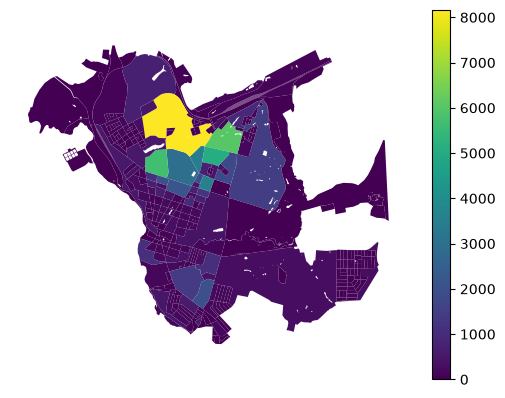

In [11]:
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.preprocessing.imputing import impute_buildings

buildings_blocks = read_cache('buildings_blocks.geojson')
if buildings_blocks is None:
    buildings = impute_buildings(buildings, default_living_demand=30)
    buildings_blocks = aggregate_objects(blocks, buildings)[0]
    write_cache(buildings_blocks.assign(block_id=buildings_blocks.index), 'buildings_blocks.geojson')
buildings_blocks = buildings_blocks.to_crs(crs)

print(f'Население города: {buildings_blocks.population.sum():,.0f} чел.')
buildings_blocks.plot('population', legend=True).set_axis_off()

## 5. Школы и обеспеченность

Школы скачиваются из OSM (`amenity=school`), вместимость достраивается конфигом BlocksNet. Обеспеченность считается конкурентной моделью `competitive_provision` по автомобильной матрице.

In [12]:
from blocksnet.preprocessing.imputing import impute_services

schools = read_cache('schools.geojson')
if schools is None:
    schools = download_features(boundaries.to_crs(4326).union_all(), {'amenity': SERVICE_TYPE})
    schools = schools[schools.geom_type.isin(['Point', 'MultiPoint', 'Polygon', 'MultiPolygon'])].reset_index(drop=True)
    schools = impute_services(schools, SERVICE_TYPE)
    write_cache(schools, 'schools.geojson')
schools = schools.to_crs(crs)

schools_blocks = read_cache('schools_blocks.geojson')
if schools_blocks is None:
    schools_blocks = aggregate_objects(blocks, schools)[0]
    write_cache(schools_blocks.assign(block_id=schools_blocks.index), 'schools_blocks.geojson')
schools_blocks = schools_blocks.to_crs(crs)

print(f'Школ: {len(schools)}, суммарная вместимость: {schools.capacity.sum():,.0f} мест')

Загружено из кэша: schools.geojson (17 объектов)
Загружено из кэша: schools_blocks.geojson (403 объектов)
Школ: 17, суммарная вместимость: 4,250 мест


school: норматив 120 мест на 1000 жителей, порог доступности 15 мин


Загружено из кэша: provision_school.geojson (403 объектов)
Средняя обеспеченность школами (provision_strong): 0.06


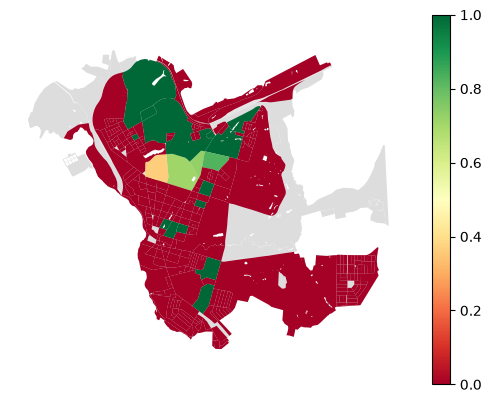

In [13]:
from blocksnet.analysis.provision import competitive_provision

service_config = service_types_config[SERVICE_TYPE]
demand = service_config['demand']
accessibility = service_config['accessibility']
print(f'{SERVICE_TYPE}: норматив {demand} мест на 1000 жителей, порог доступности {accessibility} мин')

provision_blocks = read_cache('provision_school.geojson')
if provision_blocks is None:
    provision_input = buildings_blocks[['population']].join(schools_blocks[['capacity']])
    prov_df, links_df = competitive_provision(provision_input, acc_mx, accessibility, demand)
    provision_blocks = blocks.join(prov_df)
    write_cache(provision_blocks.assign(block_id=provision_blocks.index), 'provision_school.geojson')
provision_blocks = provision_blocks.to_crs(crs)
prov_df = provision_blocks.drop(columns='geometry')

print(f'Средняя обеспеченность школами (provision_strong): {provision_blocks.provision_strong.mean():.2f}')

ax = blocks.plot(color='#dddddd')
provision_blocks.plot('provision_strong', ax=ax, cmap='RdYlGn', vmin=0, vmax=1, legend=True)
ax.set_axis_off()

## 6. Плотность и морфотипы

Показатели плотности: FSI, GSI, MXI, L, OSR. На их основе строятся морфотипы Spacematrix и Strelka.

In [14]:
from blocksnet.analysis.indicators import calculate_density_indicators

density_blocks = read_cache('density_indicators.geojson')
if density_blocks is None:
    density_input = buildings_blocks.copy()
    density_input['site_area'] = density_input.area
    density_df = calculate_density_indicators(density_input)
    density_blocks = density_input[['geometry']].join(density_df)
    write_cache(density_blocks.assign(block_id=density_blocks.index), 'density_indicators.geojson')
    density_df.to_csv(DATA_DIR / 'density_indicators.csv')
else:
    density_df = pd.read_csv(DATA_DIR / 'density_indicators.csv', index_col=0)
    density_df.index = density_df.index.astype(int)
density_blocks = density_blocks.to_crs(crs)

density_df.head()

Загружено из кэша: density_indicators.geojson (403 объектов)


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,15153.099091,3974.516695,4169.423637,483.036030,3686.387607,0.275153,0.262291,0.115852,1.049039,2.681086,0.121533,0.927506
1,13533.855457,3341.026702,4206.638727,2951.353706,1255.285021,0.310823,0.246864,0.701594,1.259086,2.423034,0.883367,0.375718
2,11531.024997,2060.448948,2872.713845,950.297921,1922.415924,0.249129,0.178687,0.330801,1.394217,3.296735,0.461209,0.933008
3,29907.050267,3727.476040,6024.235319,4442.717965,1581.517353,0.201432,0.124635,0.737474,1.616170,4.345709,1.191884,0.424286
4,29341.178957,3004.413797,3090.932386,988.924426,2102.007960,0.105345,0.102396,0.319944,1.028797,8.520654,0.329157,0.699640


Загружено из кэша: morphotypes_spacematrix.geojson (403 объектов)


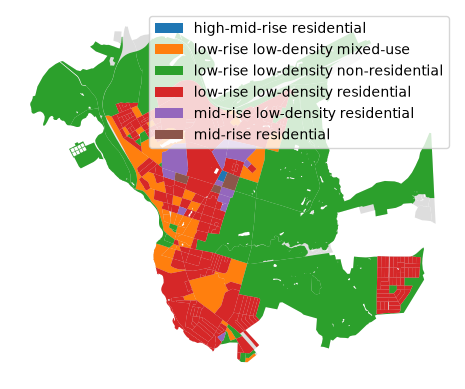

In [15]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes

spacematrix_blocks = read_cache('morphotypes_spacematrix.geojson')
if spacematrix_blocks is None:
    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
    spacematrix_df.to_csv(DATA_DIR / 'morphotypes_spacematrix.csv')
    spacematrix_clusters.to_csv(DATA_DIR / 'morphotypes_spacematrix_clusters.csv')
    spacematrix_blocks = blocks[['geometry']].join(spacematrix_df)
    write_cache(spacematrix_blocks.assign(block_id=spacematrix_blocks.index), 'morphotypes_spacematrix.geojson')
else:
    spacematrix_df = pd.read_csv(DATA_DIR / 'morphotypes_spacematrix.csv', index_col=0)
    spacematrix_df.index = spacematrix_df.index.astype(int)
spacematrix_blocks = spacematrix_blocks.to_crs(crs)

ax = blocks.plot(color='#dddddd')
spacematrix_blocks.plot('morphotype', legend=True, ax=ax)
ax.set_axis_off()

Загружено из кэша: morphotypes_strelka.geojson (403 объектов)


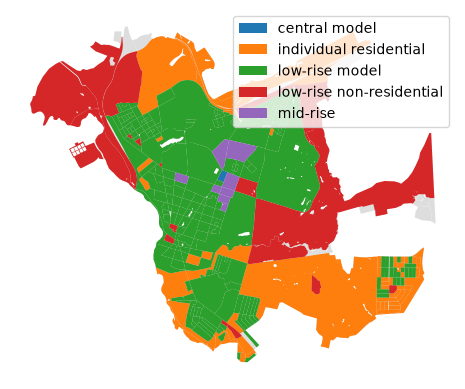

In [16]:
from blocksnet.analysis.morphotypes import get_strelka_morphotypes

strelka_blocks = read_cache('morphotypes_strelka.geojson')
if strelka_blocks is None:
    strelka_df = get_strelka_morphotypes(density_df)
    strelka_df.to_csv(DATA_DIR / 'morphotypes_strelka.csv')
    strelka_blocks = blocks[['geometry']].join(strelka_df)
    write_cache(strelka_blocks.assign(block_id=strelka_blocks.index), 'morphotypes_strelka.geojson')
else:
    strelka_df = pd.read_csv(DATA_DIR / 'morphotypes_strelka.csv', index_col=0)
    strelka_df.index = strelka_df.index.astype(int)
strelka_blocks = strelka_blocks.to_crs(crs)

ax = blocks.plot(color='#dddddd')
strelka_blocks.plot('morphotype', legend=True, ax=ax)
ax.set_axis_off()

## 7. Доступность по площади

`area_accessibility` — средневзвешенное по площади кварталов время доступности (минуты): чем меньше, тем лучше.

Загружено из кэша: area_accessibility.geojson (403 объектов)
Сохранено в кэш: area_accessibility.geojson (403 объектов)


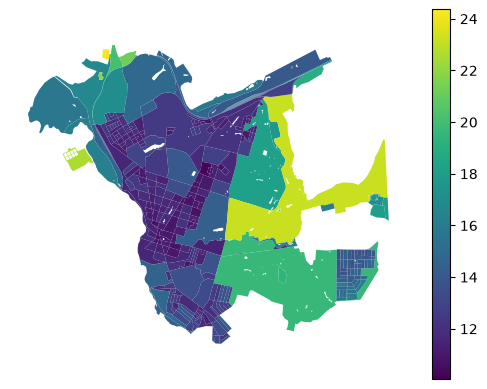

In [17]:
from blocksnet.analysis.network.accessibility import area_accessibility

area_acc_blocks = read_cache('area_accessibility.geojson')
if area_acc_blocks is None:
    area_acc_input = buildings_blocks.copy()
    area_acc_input['site_area'] = area_acc_input.area
    area_acc = area_accessibility(acc_mx, area_acc_input).rename(
        columns={'area_accessibility': 'area_accessibility_drive'}
    )
    area_acc_blocks = blocks[['geometry']].join(area_acc)
    write_cache(area_acc_blocks.assign(block_id=area_acc_blocks.index), 'area_accessibility.geojson')
else:
    area_acc = area_acc_blocks.drop(columns='geometry')
    if 'area_accessibility' in area_acc.columns:
        area_acc = area_acc.rename(columns={'area_accessibility': 'area_accessibility_drive'})
        area_acc_blocks = area_acc_blocks.rename(columns={'area_accessibility': 'area_accessibility_drive'})
        write_cache(area_acc_blocks.assign(block_id=area_acc_blocks.index), 'area_accessibility.geojson')
area_acc_blocks = area_acc_blocks.to_crs(crs)

area_acc_blocks.plot('area_accessibility_drive', legend=True).set_axis_off()

## 8. Сводные показатели

Собираем все показатели в единый `blocks_metrics.geojson` — он используется на этапе 2 (интерактивная карта и дашборд). В таблице ниже — первые 10 кварталов.

In [18]:
blocks_metrics = read_cache('blocks_metrics.geojson')
if blocks_metrics is not None and 'area_accessibility' in blocks_metrics.columns:
    blocks_metrics = blocks_metrics.rename(columns={'area_accessibility': 'area_accessibility_drive'})
    write_cache(blocks_metrics.assign(block_id=blocks_metrics.index), 'blocks_metrics.geojson')
if blocks_metrics is None:
    blocks_metrics = blocks.copy()
    blocks_metrics = blocks_metrics.join(buildings_blocks[['population']])
    blocks_metrics = blocks_metrics.join(prov_df[['demand', 'capacity', 'provision_strong', 'provision_weak']])
    blocks_metrics = blocks_metrics.join(density_df[['fsi', 'gsi', 'mxi', 'l', 'osr']])
    blocks_metrics = blocks_metrics.join(
        spacematrix_df[['cluster', 'morphotype']].rename(columns={'morphotype': 'spacematrix_morphotype'})
    )
    blocks_metrics = blocks_metrics.join(
        strelka_df[['morphotype']].rename(columns={'morphotype': 'strelka_morphotype'})
    )
    blocks_metrics = blocks_metrics.join(area_acc)
    write_cache(blocks_metrics.assign(block_id=blocks_metrics.index), 'blocks_metrics.geojson')
blocks_metrics = blocks_metrics.to_crs(crs)

blocks_metrics[[
    'population',
    'provision_strong',
    'area_accessibility_drive',
    'fsi',
    'gsi',
    'l',
    'mxi',
    'spacematrix_morphotype',
]].head(10)

Загружено из кэша: blocks_metrics.geojson (403 объектов)
Сохранено в кэш: blocks_metrics.geojson (403 объектов)


,population,provision_strong,area_accessibility_drive,fsi,gsi,l,mxi,spacematrix_morphotype
block_id,,,,,,,,
0,15.0,0.0,10.874530,0.275153,0.262291,1.049039,0.115852,low-rise low-density mixed-use
1,94.0,0.0,10.608286,0.310823,0.246864,1.259086,0.701594,low-rise low-density residential
2,30.0,0.0,10.874740,0.249129,0.178687,1.394217,0.330801,low-rise low-density mixed-use
3,137.0,0.0,11.298694,0.201432,0.124635,1.616170,0.737474,low-rise low-density residential
4,30.0,0.0,11.023060,0.105345,0.102396,1.028797,0.319944,low-rise low-density mixed-use
5,30.0,0.0,11.981967,0.108940,0.108940,1.000000,0.076829,low-rise low-density non-residential
6,1121.0,0.0,11.527714,0.260012,0.150014,1.733256,0.535163,low-rise low-density mixed-use
7,157.0,0.0,11.587067,0.228041,0.202541,1.125898,0.414562,low-rise low-density mixed-use
8,135.0,0.0,11.371894,0.124893,0.111009,1.125065,0.758181,low-rise low-density residential


## 9. Проверка результата

Проверяем, что все файлы кэша на месте и показатели согласованы между собой.

In [19]:
expected_files = [
    'boundary.geojson',
    'water.geojson',
    'roads.geojson',
    'railways.geojson',
    'blocks_raw.geojson',
    'functional_zones.geojson',
    'blocks_land_use.geojson',
    'graph_drive.pickle',
    'acc_mx_drive.csv',
    'buildings.geojson',
    'buildings_blocks.geojson',
    'schools.geojson',
    'schools_blocks.geojson',
    'provision_school.geojson',
    'density_indicators.geojson',
    'density_indicators.csv',
    'morphotypes_spacematrix.geojson',
    'morphotypes_spacematrix.csv',
    'morphotypes_spacematrix_clusters.csv',
    'morphotypes_strelka.geojson',
    'morphotypes_strelka.csv',
    'area_accessibility.geojson',
    'blocks_metrics.geojson',
]

missing = [name for name in expected_files if not (DATA_DIR / name).exists()]
assert not missing, f'Не найдены файлы кэша: {missing}'

assert len(blocks) > 0
assert len(blocks_metrics) == len(blocks)
assert 'population' in blocks_metrics.columns
assert 'area_accessibility_drive' in blocks_metrics.columns
assert acc_mx.shape == (len(blocks), len(blocks))
assert int(acc_mx.isna().sum().sum()) == 0
assert list(acc_mx.columns) == list(blocks.index)
assert blocks_metrics.index.equals(blocks.index)

print(f'Кварталов: {len(blocks)}')
print(f'Население: {blocks_metrics.population.sum():,.0f} чел.')
print(f'Средняя обеспеченность школами: {blocks_metrics.provision_strong.mean():.2f}')
print(f'Средняя доступность по площади: {blocks_metrics.area_accessibility_drive.mean():.1f} мин')
print()
print(blocks_metrics[['population', 'provision_strong', 'area_accessibility_drive', 'fsi', 'gsi', 'l', 'osr']].describe().round(2))
print()
print(f'Все {len(expected_files)} файлов кэша на месте')

Кварталов: 403
Население: 85,933 чел.
Средняя обеспеченность школами: 0.06
Средняя доступность по площади: 13.0 мин

       population  provision_strong  area_accessibility_drive     fsi     gsi       l      osr
count      403.00            281.00                    403.00  403.00  403.00  300.00   300.00
mean       213.23              0.06                     13.04    0.14    0.10    1.31    19.22
std        731.68              0.23                      2.22    0.18    0.07    0.76   160.22
min          0.00              0.00                     10.06    0.00    0.00    1.00     0.48
25%          0.00              0.00                     11.58    0.00    0.00    1.00     4.71
50%         47.00              0.00                     12.40    0.11    0.11    1.00     6.65
75%        120.00              0.00                     13.97    0.15    0.15    1.13     8.83
max       8167.00              1.00                     24.36    1.56    0.44    6.09  2738.89

Все 23 файлов кэша на месте

## 10. Повторный запуск, кэш и дальнейшие шаги

### Состав кэша `examples/data/arzamas/`

| Файл | Содержимое |
|---|---|
| `boundary.geojson` | граница города |
| `water.geojson`, `roads.geojson`, `railways.geojson` | слои OSM |
| `blocks_raw.geojson` | нарезанные кварталы |
| `functional_zones.geojson` | функциональные зоны OSM |
| `blocks_land_use.geojson` | кварталы с землепользованием |
| `graph_drive.pickle` | автомобильный граф (из OSM) |
| `acc_mx_drive.csv` | матрица времени в пути (минуты) |
| `buildings.geojson` | здания OSM |
| `buildings_blocks.geojson` | здания, агрегированные по кварталам |
| `schools.geojson`, `schools_blocks.geojson` | школы и их агрегация по кварталам |
| `provision_school.geojson` | обеспеченность школами |
| `density_indicators.geojson`, `density_indicators.csv` | показатели плотности |
| `morphotypes_spacematrix.*`, `morphotypes_strelka.*` | морфотипы |
| `area_accessibility.geojson` | доступность по площади |
| `graph_intermodal.pickle` | интермодальный граф: пешеходы + автобус (раздел 12) |
| `acc_mx_intermodal.csv` | матрица времени в пути на общественном транспорте (раздел 12) |
| `area_accessibility_intermodal.geojson` | доступность по площади: авто и общественный транспорт (раздел 12) |
| `blocks_metrics.geojson` | **все показатели (вход для этапа 2)** |

### Повторный запуск

- Запустите ноутбук заново сверху вниз — всё возьмётся из кэша, быстро.
- Чтобы пересчитать конкретный шаг, удалите соответствующий файл кэша и запустите ячейку снова.
- Чтобы сменить сервис: поменяйте `SERVICE_TYPE` в первой ячейке, удалите `schools.geojson`, `schools_blocks.geojson`, `provision_school.geojson` и запустите разделы 5+ заново.
- Чтобы пересчитать матрицу (например, после правки кварталов): удалите `acc_mx_drive.csv`.
- Раздел 12 (приложение, общественный транспорт) дополняет ноутбук до полного примера BlocksNet: он строит интермодальную матрицу и добавляет колонки доступности и обеспеченности по общественному транспорту. Для этапа 2 он не обязателен.

### Этап 2

Когда все ячейки выполнены, файл `blocks_metrics.geojson` готов. На следующем этапе отдельный скрипт соберёт из него одну HTML-страницу: интерактивную карту и дашборд с графиками и выводами.

## 11. Словарь показателей (шпаргалка)

Этот раздел — справочник. Здесь простыми словами объясняется, что означают все показатели пайплайна и какие метрики вообще умеет BlocksNet. Числа — из текущего прогона по Арзамасу.

### 11.1. Какие метрики есть в BlocksNet

| Группа | Что считает | Примеры показателей |
|---|---|---|
| Плотность и морфология | насколько плотно и как высоко застроены кварталы, какой у них «характер» | FSI, GSI, MXI, L, OSR; морфотипы Spacematrix и Strelka |
| Геометрия и разнообразие | размер и форма кварталов, разнообразие застройки | площади и длины кварталов, центры; индекс разнообразия Шеннона |
| Центральность | какие кварталы — «центры притяжения» людей и сервисов | центральность по населению и по услугам |
| Транспорт и доступность | сколько ехать между кварталами и насколько квартал достижим из всех остальных | матрица времени поездок, доступность по площади, связность сети, потоки «источник — цель», загруженность дорог |
| Обеспеченность сервисами | хватает ли школ, садиков и других услуг и укладываются ли они в норматив по времени | конкурентная и кооперативная обеспеченность, плотность и совместное расположение сервисов |
| Землепользование | какие функции где расположены | доли зон, совместная встречаемость функций, сходство кварталов, прогноз функций |
| Социально-экономические показатели | готовый каталог городской статистики из 8 групп: демография, экономика, экология, инженерная инфраструктура, социальные услуги, транспорт, расселение, общие показатели | плотность населения (чел/км²), плотность дорог (км/км²), доступность остановок (мин), ГРП на жителя и др. |
| Инструменты | подготовка данных и планирование | нарезка кварталов, достройка зданий, населения и услуг, поиск свободных территорий, оптимизация размещения сервисов |

В конфиге BlocksNet — 82 типа сервисов с нормативами (например, школа: 120 мест на 1000 жителей, порог доступности 15 минут — именно эти нормативы использованы в нашем расчёте).

### 11.2. Все показатели нашего пайплайна

Главный итоговый файл — `blocks_metrics.geojson` (403 квартала). Ниже — каждая колонка.

**Кварталы и население**

| Показатель | Что означает | Единицы | В Арзамасе |
|---|---|---|---|
| `block_id` | номер квартала, по которому соединяются все таблицы | № | 403 квартала |
| `population` | сколько человек живёт в квартале — оценка по жилой площади зданий | человек | 85 933 чел. всего; в среднем 213; максимум 8 167; люди есть в 281 квартале из 403 |
| `land_use` | главная функция квартала по зонам из OSM | категория | жилая — 271 (67%), промышленная — 29, деловая — 5, без данных — 91 |
| `residential` … `agriculture` | доля площади квартала под каждой функциональной зоной (жилая, деловая, рекреация, промышленная, транспорт, спец., сельхоз) | доля 0–1 | жилая зона — самая распространённая; транспорт и сельхоз почти не встречаются |
| `share` | какая доля квартала приходится на главную зону | доля 0–1 | определена у 312 кварталов |

Примечание: в разделе 2 подпись «нет данных 403» — особенность отображения при чтении из кэша; в файлах данных зоны размечены нормально (см. таблицу выше).

**Доступность (поездки на автомобиле по дорогам OSM)**

| Показатель | Что означает | Единицы | В Арзамасе |
|---|---|---|---|
| `acc_mx_drive.csv` | время поездки между каждой парой кварталов (матрица 403×403) | минуты | в среднем 9.1 мин между двумя кварталами |
| `area_accessibility_drive` | средневзвешенное по площади время, за которое квартал достижим из всех остальных (чем меньше — тем «центральнее») | минуты | в среднем 13.0 мин; от 10 до 24 |

Примечание: в разделе 12 (приложение) добавлены ещё два показателя доступности — `acc_mx_intermodal.csv` и колонка `area_accessibility_intermodal` (минуты на общественном транспорте с пешими переходами); там же — `provision_strong_intermodal` и `provision_weak_intermodal` (обеспеченность школами по общественному транспорту). В официальном примере BlocksNet итоговые доступность и обеспеченность показаны именно по общественному транспорту.

**Обеспеченность школами**

| Показатель | Что означает | Единицы | В Арзамасе |
|---|---|---|---|
| `demand` | сколько школьных мест нужно кварталу по нормативу 120 мест на 1000 жителей | мест | 10 449 мест суммарно |
| `capacity` | суммарная вместимость школ квартала (вместимость из OSM дозаполнена конфигом BlocksNet) | мест | 4 250 мест, 17 школ |
| `provision_strong` | доля потребности, покрытая школами в пределах 15 минут езды | доля 0–1 | в среднем 0.06 — покрыто лишь ~6% потребности, школьных мест городу не хватает |
| `provision_weak` | то же, но засчитываются и школы дальше 15 минут | доля 0–1 | 0.06 — вместимости не хватает даже без ограничения по времени |

Для 122 кварталов без жителей обеспеченность пустая (NaN): нет спроса — нечего считать.

**Плотность застройки** (считается у 300 застроенных кварталов)

| Показатель | Что означает | Единицы | В Арзамасе |
|---|---|---|---|
| `fsi` | вся поэтажная площадь зданий на 1 м² земли квартала («сколько зданий») | м²/м² | в среднем 0.14 — застройка разреженная; максимум 1.56 |
| `gsi` | доля земли, занятая зданиями (пятно застройки) | доля 0–1 | 0.10 — здания занимают ~10% земли |
| `mxi` | какая часть зданий — жильё | доля 0–1 | 0.66 — город преимущественно жилой |
| `l` | средняя этажность застройки | этажей | 1.31 — почти всё одноэтажное |
| `osr` | сколько открытой (свободной от зданий) земли на 1 м² построек | м²/м² | медиана ~6.7 — открытых пространств очень много |

**Морфотипы** (типы «характера» застройки)

| Показатель | Что означает | Единицы | В Арзамасе |
|---|---|---|---|
| `cluster` | номер кластера (0–10), к которому KMeans отнёс квартал по fsi, l, mxi | № | у 300 застроенных кварталов |
| `spacematrix_morphotype` | название типа квартала по кластеру: этажность + плотность + функция | категория | 214 — малоэтажный разреженный жилой; 36 — нежилой; 35 — смешанный; далее средн этажные типы (11 + 3 + 1) |
| `strelka_morphotype` | тип застройки по правилам Strelka KB (по l, fsi, mxi) | категория | 211 — «low-rise model»; 58 — индивидуальная жилая; 22 — нежилые малоэтажки; 8 — средн этажные; 1 — центральный тип |

У кварталов без построек морфотип пустой.

**Вспомогательные поля зданий** (`buildings_blocks.geojson`; из них считаются показатели выше)

| Показатель | Что означает | Единицы |
|---|---|---|
| `is_living` | считается ли здание жилым | да/нет |
| `number_of_floors` | этажность (из OSM; неизвестная дозаполняется) | этажей |
| `footprint_area` | площадь застройки здания | м² |
| `build_floor_area` | вся поэтажная площадь (площадь × этажность) | м² |
| `living_area` | жилая площадь (у жилых — 0.9 от поэтажной) | м² |
| `non_living_area` | нежилая площадь | м² |

**Как читать:** пустое значение (NaN) значит «данных нет или показатель неприменим» — обеспеченность считается только там, где живут люди, морфотип — только у застроенных кварталов. Доли 0–1 можно умножать на 100 и читать как проценты.

## 12. Приложение: общественный транспорт (интермодальная доступность)

Этот раздел дополняет ноутбук до полного набора показателей официального примера BlocksNet (Санкт-Петербург). В примере считаются **две** матрицы времени в пути, и обе используются в анализе:

- `acc_mx_drive` — на автомобиле (посчитана в разделе 3);
- `acc_mx_intermodal` — на общественном транспорте с учётом пеших переходов («интермодальная»). В примере именно по ней показана итоговая доступность по площади, и именно по ней там посчитана обеспеченность школами.

Мы повторим это для Арзамаса. Что произойдёт при выполнении ячеек этого раздела:

1. **Граф.** Из OpenStreetMap построится интермодальный граф: пешеходная сеть + маршруты автобусов; остановки «сшиваются» с пешеходными дорожками. Сохранится в `graph_intermodal.pickle`. Для Арзамаса качаем только автобусные маршруты — в примере качаются все виды транспорта, но для небольшого города автобусов достаточно.
2. **Матрица.** По графу посчитается матрица времени между всеми парами кварталов (минуты) — `acc_mx_intermodal.csv`. Внизу — сравнение среднего времени: автомобиль против общественного транспорта.
3. **Доступность по площади** сразу по двум матрицам (как в примере): файл `area_accessibility_intermodal.geojson` с колонками `area_accessibility_drive` и `area_accessibility_intermodal`, плюс две карты рядом.
4. **Сводные показатели.** В `blocks_metrics.geojson` добавится колонка `area_accessibility_intermodal` — остальные колонки не меняются.
5. **Обеспеченность школами (необязательно).** Обеспеченность, посчитанная на интермодальной матрице (как в примере): добавятся `provision_strong_intermodal` и `provision_weak_intermodal`, плюс карта и сравнение с автомобильным вариантом.

**Как выполнить:** либо целиком — `Cell → Run All` (данные возьмутся из кэша, это быстро, а ячейки этого раздела выполнятся последними); либо только этот раздел — сначала выполните самую первую кодовую ячейку ноутбука (настройки и импорты), затем все ячейки раздела 12 по порядку.

**Важно знать:**

- Интернет нужен только ячейке с построением графа. Overpass-серверы, из которых берутся данные OSM, часто перегружены — ячейка сама делает до 15 попыток с паузами. Если она всё же не смогла — просто запустите её позже: это ничего не сломает.
- Если в OSM не найдётся автобусных маршрутов, библиотека предупредит и вернёт только пешеходный граф — тогда времена будут близки к пешим (медленнее автомобильных).
- Всё кэшируется: `graph_intermodal.pickle` и `acc_mx_intermodal.csv` при повторных запусках не пересчитываются.
- На этап 2 (дашборд) раздел не влияет: дашборд продолжит работать как раньше.

In [20]:
import iduedu.modules.downloaders as iduedu_downloaders
from iduedu import config as iduedu_config
from iduedu.enums.pt_enums import PublicTrasport

from blocksnet.relations import get_accessibility_graph

_ORIGINAL_REQUESTS = iduedu_downloaders.requests
_OSM_USER_AGENT = 'ArzamasBlocksNet/1.0 (educational research; unique user agent)'


class _RequestsWithUserAgent:
    @staticmethod
    def get(url, **kwargs):
        headers = dict(kwargs.pop('headers', {}) or {})
        headers.setdefault('User-Agent', _OSM_USER_AGENT)
        return _ORIGINAL_REQUESTS.get(url, headers=headers, **kwargs)

    @staticmethod
    def post(url, **kwargs):
        headers = dict(kwargs.pop('headers', {}) or {})
        headers.setdefault('User-Agent', _OSM_USER_AGENT)
        return _ORIGINAL_REQUESTS.post(url, headers=headers, **kwargs)


iduedu_downloaders.requests = _RequestsWithUserAgent

boundaries = read_cache('boundary.geojson')

graph_intermodal_path = DATA_DIR / 'graph_intermodal.pickle'
if graph_intermodal_path.exists():
    with open(graph_intermodal_path, 'rb') as file:
        graph_intermodal = pickle.load(file)
    print(f'Граф загружен из кэша: {graph_intermodal_path.name}')
else:
    log_download('Строим интермодальный граф (пешеходная сеть + маршруты автобусов) из OSM...')
    iduedu_config.timeout = 240
    for attempt in range(18):
        try:
            url = OVERPASS_URLS[attempt % len(OVERPASS_URLS)]
            ox.settings.overpass_url = url
            iduedu_config.overpass_url = url + '/interpreter'
            graph_intermodal = get_accessibility_graph(
                boundaries, 'intermodal', transport_types=[PublicTrasport.BUS]
            )
            break
        except Exception as error:
            wait = min(30 * (attempt + 1), 180)
            detail = ' '.join(str(error).split())[:110]
            log_download(f'Интермодальный граф не построился ({type(error).__name__}: {detail}), пауза {wait} с и пробуем снова...')
            time.sleep(wait)
    else:
        raise RuntimeError('Не удалось построить интермодальный граф: все Overpass-серверы заняты, попробуйте запустить позже')
    with open(graph_intermodal_path, 'wb') as file:
        pickle.dump(graph_intermodal, file)
    print(f'Граф сохранён в кэш: {graph_intermodal_path.name} ({graph_intermodal_path.stat().st_size / 1e6:.1f} МБ)')

print(f'Узлов: {graph_intermodal.number_of_nodes():,}, рёбер: {graph_intermodal.number_of_edges():,}')

_, node_data = next(iter(graph_intermodal.nodes(data=True)))
assert 'x' in node_data and 'y' in node_data, 'в узлах графа нет координат x/y'
edge_attributes = next(iter(graph_intermodal.edges(keys=False, data=True)))[2]
assert 'time_min' in edge_attributes, 'в рёбрах графа нет времени time_min'
print('Граф корректен: в узлах есть координаты x/y, в рёбрах — время time_min (минуты)')

Загружено из кэша: boundary.geojson (1 объектов)


Граф загружен из кэша: graph_intermodal.pickle
Узлов: 6,048, рёбер: 17,103
Граф корректен: в узлах есть координаты x/y, в рёбрах — время time_min (минуты)


In [21]:
from blocksnet.relations import calculate_accessibility_matrix

blocks = read_cache('blocks_raw.geojson')
crs = blocks.estimate_utm_crs()
blocks = blocks.to_crs(crs)


def _clean_matrix(matrix):
    values = matrix.to_numpy(dtype=float, copy=True)
    finite_max = float(values[np.isfinite(values)].max())
    values[~np.isfinite(values)] = finite_max
    np.fill_diagonal(values, 0.0)
    return pd.DataFrame(values, index=matrix.index, columns=matrix.columns)


acc_mx_drive = _clean_matrix(read_matrix('acc_mx_drive.csv'))

acc_mx_intermodal = read_matrix('acc_mx_intermodal.csv')
if acc_mx_intermodal is None:
    print('Считаем матрицу времени в пути на общественном транспорте (минуты)...')
    acc_mx_intermodal = calculate_accessibility_matrix(blocks, graph_intermodal)
    write_matrix(acc_mx_intermodal, 'acc_mx_intermodal.csv')
acc_mx_intermodal = _clean_matrix(acc_mx_intermodal)

assert acc_mx_intermodal.shape == (len(blocks), len(blocks))
assert int(acc_mx_intermodal.isna().sum().sum()) == 0
assert list(acc_mx_intermodal.index) == list(blocks.index)

print(f'Матрица готова: {acc_mx_intermodal.shape[0]} x {acc_mx_intermodal.shape[1]} кварталов')
print(f'Среднее время в пути на автомобиле: {acc_mx_drive.to_numpy().mean():.1f} мин')
print(f'Среднее время в пути на общественном транспорте: {acc_mx_intermodal.to_numpy().mean():.1f} мин')

Загружено из кэша: blocks_raw.geojson (403 объектов)


Загружено из кэша: acc_mx_drive.csv (403, 403)


Загружено из кэша: acc_mx_intermodal.csv (403, 403)
Матрица готова: 403 x 403 кварталов
Среднее время в пути на автомобиле: 9.1 мин
Среднее время в пути на общественном транспорте: 32.5 мин


Загружено из кэша: area_accessibility_intermodal.geojson (403 объектов)


Доступность по площади, автомобиль: 13.0 мин
Доступность по площади, общественный транспорт: 39.9 мин


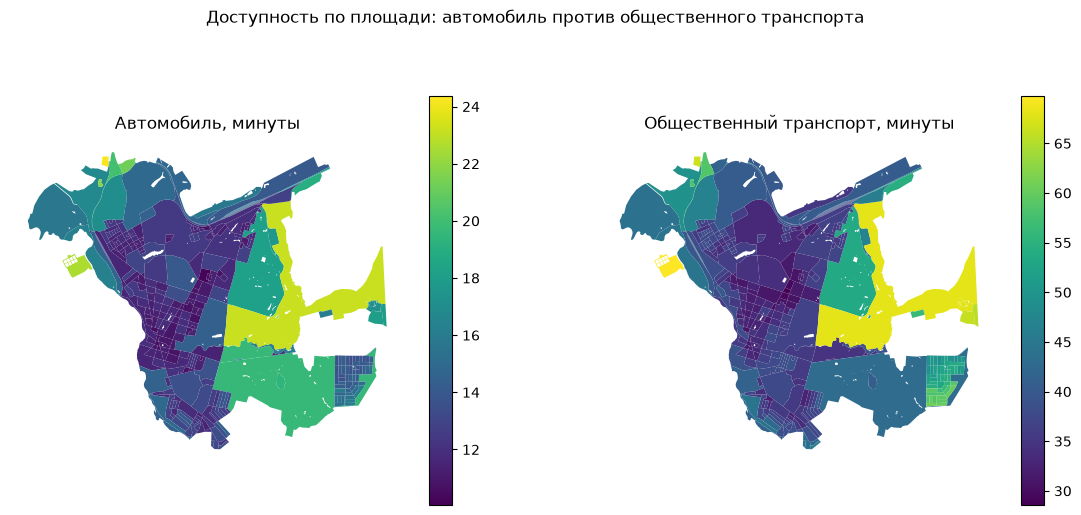

In [22]:
import matplotlib.pyplot as plt

from blocksnet.analysis.network.accessibility import area_accessibility

area_acc_dual = read_cache('area_accessibility_intermodal.geojson')
if area_acc_dual is None:
    buildings_blocks = read_cache('buildings_blocks.geojson').to_crs(crs)
    area_acc_input = buildings_blocks.copy()
    area_acc_input['site_area'] = area_acc_input.area
    area_acc_drive = area_accessibility(acc_mx_drive, area_acc_input).rename(
        columns={'area_accessibility': 'area_accessibility_drive'}
    )
    area_acc_intermodal = area_accessibility(acc_mx_intermodal, area_acc_input).rename(
        columns={'area_accessibility': 'area_accessibility_intermodal'}
    )
    area_acc_dual = blocks[['geometry']].join(area_acc_drive).join(area_acc_intermodal)
    write_cache(area_acc_dual.assign(block_id=area_acc_dual.index), 'area_accessibility_intermodal.geojson')

area_acc_plot = area_acc_dual.to_crs(crs)
figure, axes = plt.subplots(1, 2, figsize=(14, 6))
area_acc_plot.plot('area_accessibility_drive', ax=axes[0], legend=True)
axes[0].set_title('Автомобиль, минуты')
axes[0].set_axis_off()
area_acc_plot.plot('area_accessibility_intermodal', ax=axes[1], legend=True)
axes[1].set_title('Общественный транспорт, минуты')
axes[1].set_axis_off()
figure.suptitle('Доступность по площади: автомобиль против общественного транспорта')

print(f'Доступность по площади, автомобиль: {area_acc_dual.area_accessibility_drive.mean():.1f} мин')
print(f'Доступность по площади, общественный транспорт: {area_acc_dual.area_accessibility_intermodal.mean():.1f} мин')

In [23]:
blocks_metrics = read_cache('blocks_metrics.geojson')
area_acc_dual = read_cache('area_accessibility_intermodal.geojson')

if 'area_accessibility_intermodal' not in blocks_metrics.columns:
    blocks_metrics = blocks_metrics.join(area_acc_dual[['area_accessibility_intermodal']])
    write_cache(blocks_metrics.assign(block_id=blocks_metrics.index), 'blocks_metrics.geojson')
    print('В blocks_metrics.geojson добавлена колонка area_accessibility_intermodal')
else:
    print('Колонка area_accessibility_intermodal уже есть в blocks_metrics.geojson')

blocks_metrics[[
    'population',
    'provision_strong',
    'area_accessibility_drive',
    'area_accessibility_intermodal',
    'fsi',
    'mxi',
    'spacematrix_morphotype',
]].head(10)

Загружено из кэша: blocks_metrics.geojson (403 объектов)
Загружено из кэша: area_accessibility_intermodal.geojson (403 объектов)
Колонка area_accessibility_intermodal уже есть в blocks_metrics.geojson


,population,provision_strong,area_accessibility_drive,area_accessibility_intermodal,fsi,mxi,spacematrix_morphotype
block_id,,,,,,,
0,15.0,0.0,10.874530,31.902510,0.275153,0.115852,low-rise low-density mixed-use
1,94.0,0.0,10.608286,31.211362,0.310823,0.701594,low-rise low-density residential
2,30.0,0.0,10.874740,32.546622,0.249129,0.330801,low-rise low-density mixed-use
3,137.0,0.0,11.298694,32.969425,0.201432,0.737474,low-rise low-density residential
4,30.0,0.0,11.023060,33.603362,0.105345,0.319944,low-rise low-density mixed-use
5,30.0,0.0,11.981967,35.653633,0.108940,0.076829,low-rise low-density non-residential
6,1121.0,0.0,11.527714,39.153366,0.260012,0.535163,low-rise low-density mixed-use
7,157.0,0.0,11.587067,35.990596,0.228041,0.414562,low-rise low-density mixed-use
8,135.0,0.0,11.371894,33.310624,0.124893,0.758181,low-rise low-density residential


2026-10-19 18:15:36.899 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame


Загружено из кэша: buildings_blocks.geojson (403 объектов)
Загружено из кэша: schools_blocks.geojson (403 объектов)


2026-10-19 18:15:36.902 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter


2026-10-19 18:15:36.923 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-10-19 18:15:36.934 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


2026-10-19 18:15:37.309 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Загружено из кэша: blocks_metrics.geojson (403 объектов)
Колонки provision_strong_intermodal/provision_weak_intermodal уже есть в blocks_metrics.geojson
Обеспеченность школами, автомобиль: 0.06
Обеспеченность школами, общественный транспорт: 0.20


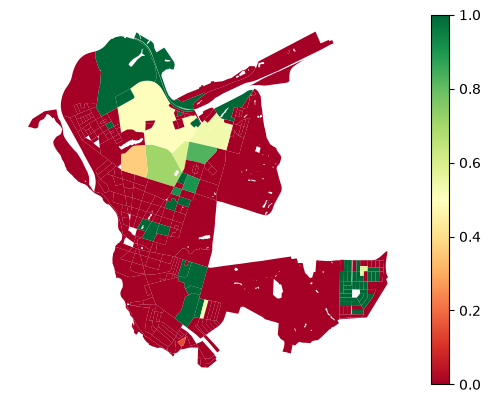

In [24]:
from blocksnet.analysis.provision import competitive_provision

service_config = service_types_config[SERVICE_TYPE]
buildings_blocks = read_cache('buildings_blocks.geojson').to_crs(crs)
schools_blocks = read_cache('schools_blocks.geojson').to_crs(crs)

provision_input = buildings_blocks[['population']].join(schools_blocks[['capacity']])
prov_intermodal, _ = competitive_provision(
    provision_input, acc_mx_intermodal, service_config['accessibility'], service_config['demand']
)

blocks_metrics = read_cache('blocks_metrics.geojson')
if 'provision_strong_intermodal' not in blocks_metrics.columns:
    prov_columns = prov_intermodal[['provision_strong', 'provision_weak']].rename(
        columns={'provision_strong': 'provision_strong_intermodal', 'provision_weak': 'provision_weak_intermodal'}
    )
    blocks_metrics = blocks_metrics.join(prov_columns)
    write_cache(blocks_metrics.assign(block_id=blocks_metrics.index), 'blocks_metrics.geojson')
    print('В blocks_metrics.geojson добавлены provision_strong_intermodal и provision_weak_intermodal')
else:
    print('Колонки provision_strong_intermodal/provision_weak_intermodal уже есть в blocks_metrics.geojson')

provision_plot = blocks[['geometry']].join(
    prov_intermodal[['provision_strong']].rename(columns={'provision_strong': 'provision_strong_intermodal'})
)
provision_plot.plot('provision_strong_intermodal', cmap='RdYlGn', vmin=0, vmax=1, legend=True).set_axis_off()

print(f'Обеспеченность школами, автомобиль: {blocks_metrics.provision_strong.mean():.2f}')
print(f'Обеспеченность школами, общественный транспорт: {blocks_metrics.provision_strong_intermodal.mean():.2f}')